## Imports and Reading Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import statsmodels.api as sm
from patsy import dmatrices
from scipy.stats import norm
# ignore futurewarning
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)

In [2]:
customers = pd.read_csv('../data/raw/customers.csv')
responses = pd.read_csv('../data/raw/responses.csv')
views = pd.read_csv('../data/raw/views.csv')

In [3]:
responses.sample(5)

,customer_id,segment,offer,resubscribed_promo,resub_day
364153,364154,Low,Discount,0,NaN
120022,120023,High,Early Access,0,NaN
415154,415155,Low,Discount,0,NaN
420366,420367,Medium,Discount,0,NaN
163864,163865,Low,Control,0,NaN


## Analysis 1 - Campaign Incrementality

The intent behind this analysis is to understand whether the offers, overall, had any effect at all on the audience - and if it did, how much impact did it have. A good way to think about this is - if I had not given any offers would my population still resubscribe at the same rate? - if not, how much incremental resubscription was brought in by the offers?

So, if I had a total of 500 churned customers - without offers, maybe 80 of them would have resubscribed. With the offers, let's say 150 of them resubscribed. What we want to know here is - how many of those 150 resubscribed just because of the offer?

This will help the company decide the impact of offers overall - and whether or not providing offers to churned customers is worth it or not.

In [4]:
# Creating a df for this specific analysis
inc_analysis_df = responses.copy()
inc_analysis_df.sample(5)

,customer_id,segment,offer,resubscribed_promo,resub_day
232014,232015,Low,Early Access,0,NaN
108843,108844,Low,Early Access,0,NaN
324354,324355,High,Early Access,0,NaN
317847,317848,High,Free Trial,0,NaN
381343,381344,Low,Early Access,0,NaN


In [5]:
# Creating a 'control' column - that is 1 for the control group (no offers or marketing received) and 0 for the treatment group (who received offers)
inc_analysis_df['control'] = inc_analysis_df['offer'].apply(lambda x: 1 if x == 'Control' else 0)
inc_analysis_df['control'].value_counts()

control
0    450002
1     49998
Name: count, dtype: int64

Now our required columns look like this 

| control | segment | resubscribed_promo |
|---|---|---|

We have 500K rows. `resubscribed_promo` is our dependent variable. `control` and `segment` are our independent variables. The question we are trying to answer is - within each segment (high/medium/low), did the control population react to the offer?

#### Building the model

In [6]:
# Building the model - Our outcome is binary (resubscribed or not), and we have a mix of segments that we sent offers to and whether or not they were targeted.
formula = (
    'resubscribed_promo ~ control * segment'
)
y, X = dmatrices(formula, inc_analysis_df, return_type='dataframe')

model = sm.Logit(y, X).fit()

Optimization terminated successfully.
         Current function value: 0.443810
         Iterations 7


In [7]:
# Within the model, we want to sense-check the distribution of our dependent variable
resp_profile = inc_analysis_df[model.model.endog_names].value_counts().sort_index(ascending=False)

resp_profile_df = pd.DataFrame({
    'Ordered Value': range(1, len(resp_profile) + 1),
    model.model.endog_names: resp_profile.index,
    'Total': resp_profile.values
})

resp_profile_df

,Ordered Value,resubscribed_promo,Total
0,1,1,83656
1,2,0,416344


In [8]:
# Creating a dataframe with the model results
summary_df = pd.DataFrame({
    'variable': model.params.index,
    'coef': model.params.values,
    'std err': model.bse.values,
    'z': model.tvalues.values,
    'p-value': model.pvalues.values
})
summary_df

,variable,coef,std err,z,p-value
0,Intercept,-1.072979,0.008833,-121.480490,0.000000e+00
1,segment[T.Low],-0.487781,0.010442,-46.714187,0.000000e+00
2,segment[T.Medium],-0.652745,0.011289,-57.822497,0.000000e+00
3,control,-1.138314,0.039590,-28.752698,8.380820e-182
4,control:segment[T.Low],-0.066203,0.048197,-1.373581,1.695718e-01
5,control:segment[T.Medium],0.407937,0.048928,8.337424,7.592613e-17


For our analysis, what we look at here are the p-values. a p-value that is higher than our significance threshold (a = 0.10) indicates that the variable is not significant, and can be dropped. In this case, all the p-values are lower than 0.1, so we proceed with all of them in the model

In [9]:
X.columns

Index(['Intercept', 'segment[T.Low]', 'segment[T.Medium]', 'control',
       'control:segment[T.Low]', 'control:segment[T.Medium]'],
      dtype='object')

#### Wald chi-square test for each effect
here, we want to test whether each of the input variables in the model are jointly significant. What this helps with is - if the independent variable has multiple levels - like in this case, segment has high medium and low. It is likely that the 'Low' gets a significant p-value but 'medium' and 'high' do not - we do not know if the overall 'segment' variable is significant. This test gives us that significance.

In [10]:
# Get all parameter names
param_names = X.columns

# Get number of levels for categorical variables
n_control = inc_analysis_df['control'].nunique()
n_segment = inc_analysis_df['segment'].nunique()

#Main Columns
control_cols = [col for col in param_names if col.startswith('control') and ':' not in col]
segment_cols = [col for col in param_names if col.startswith('segment') and ':' not in col]

# Interaction Columns
interaction_cols = [col for col in param_names if ':' in col]

# Calculate DF
df_control = n_control - 1
df_segment = n_segment - 1
df_interaction = df_control * df_segment

#Results
joint_tests = []

if control_cols:
    test = model.wald_test(np.eye(len(param_names))[ [param_names.get_loc(col) for col in control_cols]])
    joint_tests.append(['control', df_control, test.statistic[0][0], test.pvalue])

if segment_cols:
    test = model.wald_test(np.eye(len(param_names))[ [param_names.get_loc(col) for col in segment_cols]])
    joint_tests.append(['segment', df_segment, test.statistic[0][0], test.pvalue])

if interaction_cols:
    test = model.wald_test(np.eye(len(param_names))[ [param_names.get_loc(col) for col in interaction_cols]])
    joint_tests.append(['interaction', df_interaction, test.statistic[0][0], test.pvalue])

joint_df = pd.DataFrame(joint_tests, columns=['Type', 'DF', 'Wald-Chisq Statistic', 'P-Value'])
joint_df['Significant'] = joint_df['P-Value'] < 0.01

joint_df

,Type,DF,Wald-Chisq Statistic,P-Value,Significant
0,control,1,826.717625,8.380819676848794e-182,True
1,segment,2,3470.359767,0.0,True
2,interaction,2,155.166368,2.023257668407754e-34,True


#### Getting the predicted values

In the model output - we received coefficients. These coefficients are log-odds and are not directly interpretable. What we need is the actual predicted probabilities and not the log odds.

This step helps us see what the model predicted for each segment individually. So we have 2 (control) values and 3 (segment) values. That would give us a total of 6 contrast statements - basically what's the response rate that the model predicted for Control population High segment and so on.


In [11]:
X.columns

Index(['Intercept', 'segment[T.Low]', 'segment[T.Medium]', 'control',
       'control:segment[T.Low]', 'control:segment[T.Medium]'],
      dtype='object')

In [12]:
X

,Intercept,segment[T.Low],segment[T.Medium],control,control:segment[T.Low],control:segment[T.Medium]
0,1.0,1.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,1.0,0.0,0.0,0.0
3,1.0,0.0,1.0,0.0,0.0,0.0
4,1.0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...
499995,1.0,0.0,1.0,0.0,0.0,0.0
499996,1.0,0.0,0.0,0.0,0.0,0.0
499997,1.0,1.0,0.0,0.0,0.0,0.0
499998,1.0,0.0,1.0,0.0,0.0,0.0


In [13]:
# Building the 6 predicted groups for the predicted probabilities
contrast_rows = {
    'Control High':{
        'Intercept':1,
        'segment[T.Low]':0,
        'segment[T.Medium]':0,
        'control':1,
        'control:segment[T.Low]':0,
        'control:segment[T.Medium]':0
    },
    'Control Medium':{
        'Intercept':1,
        'segment[T.Low]':0,
        'segment[T.Medium]':1,
        'control':1,
        'control:segment[T.Low]':0,
        'control:segment[T.Medium]':1
    },
    'Control Low':{
        'Intercept':1,
        'segment[T.Low]':1,
        'segment[T.Medium]':0,
        'control':1,
        'control:segment[T.Low]':1,
        'control:segment[T.Medium]':0
    },
    'Offer High':{
        'Intercept':1,
        'segment[T.Low]':0,
        'segment[T.Medium]':0,
        'control':0,
        'control:segment[T.Low]':0,
        'control:segment[T.Medium]':0
    },
    'Offer Medium':{
        'Intercept':1,
        'segment[T.Low]':0,
        'segment[T.Medium]':1,
        'control':0,
        'control:segment[T.Low]':0,
        'control:segment[T.Medium]':0
    },
    'Offer Low':{
        'Intercept':1,
        'segment[T.Low]':1,
        'segment[T.Medium]':0,
        'control':0,
        'control:segment[T.Low]':0,
        'control:segment[T.Medium]':0
    },    
}

predicted_probs = {}
for label, row in contrast_rows.items():
    contrast_X = pd.DataFrame([row], columns=X.columns)
    pred = model.get_prediction(contrast_X)
    summary = pred.summary_frame(alpha=0.1)
    predicted_probs[label] = {
        'predicted': summary['predicted'][0],
        'se': summary['se'][0],
        'ci_lower': summary['ci_lower'][0],
        'ci_upper': summary['ci_upper'][0]
    }

predicted_df = pd.DataFrame(predicted_probs).T.reset_index().rename(columns={'index':'Contrast'})
predicted_df

,Contrast,predicted,se,ci_lower,ci_upper
0,Control High,0.098741,0.003434,0.093234,0.104536
1,Control Medium,0.078993,0.002028,0.075721,0.082395
2,Control Low,0.059230,0.001500,0.056810,0.061745
3,Offer High,0.254837,0.001677,0.252088,0.257606
4,Offer Medium,0.151135,0.000902,0.149658,0.152625
5,Offer Low,0.173538,0.000799,0.172228,0.174855


#### Incremental Factors and significance for each segment

Here, we see the actual Incremental effect. We want to see the offer population vs the control (no offer) population, for each segment. This is done using the vectors we defined in the previous step.
We also see whether each of the differences are statistically significant using the bonferroni test.

The output gives us the p-values for significance, and the lift generated in each segment (offer - control) / control


In [14]:

params = model.params
cov = model.cov_params()

contrast_vectors = {'High Offer - Control': np.array([0, 0, 0, -1, 0, 0]),
                    'Medium Offer - Control': np.array([0, 0, 0, -1, 0, -1]),
                    'Low Offer - Control': np.array([0, 0, 0, -1, -1, 0])
}

# Z critical value for 95% confidence
z_crit = norm.ppf(0.975)

# Number of comparisons for Bonferroni correction
k = len(contrast_vectors)

rows = []
for label, contrast in contrast_vectors.items():
    est = np.dot(contrast, params)
    se = np.sqrt(np.dot(contrast.T, np.dot(cov, contrast)))
    z_val = est / se
    p_val = 2 * (1 - norm.cdf(abs(z_val)))
    
    #Bonferroni correction
    p_val_bonf = min(p_val * k, 1)
    
    #Seheffe adjustment 
    p_val_scheffe = 1 - (1 - p_val) ** k
    
    lower = est - z_crit * se
    upper = est + z_crit * se
    exp_est = np.exp(est)
    exp_lower = np.exp(lower)
    exp_upper = np.exp(upper)
    
    # These lifts and incremenal factors are calcualted in the odds space. If our incidence rate was lower, we could have calculated the lifts and incrementals correctly in this space, but given our high incidence rate(>10%), these will give exaggerated values and not be reflective of the true lift and incremental factor in the probability space.
    # lift = (exp_est - 1)*100 # (treatment - control) / control
    # factor = round((1 - (1 / (lift/100 + 1)))*100) # (treatment - control) / treatment

    # Extract segment name from label
    segment = label.split()[0]
    control_key = f'Control {segment}'
    offer_key = f'Offer {segment}'
    

    # Get predicted probabilities
    control_prob = predicted_df[predicted_df['Contrast'] == control_key]['predicted'].values[0]
    offer_prob = predicted_df[predicted_df['Contrast'] == offer_key]['predicted'].values[0]
    
    # Calculate lift and factor in probability space
    lift = f"{round(((offer_prob - control_prob) / control_prob) * 100)}%"
    factor = round(((offer_prob - control_prob) / offer_prob) * 100,2)
    
    rows.append([label, est, se, z_val, p_val, p_val_bonf, p_val_scheffe, lower, upper, exp_est, exp_lower, exp_upper, lift, factor])

result_df = pd.DataFrame(rows, columns=[
    'Comparison', 
    'Estimate',
    'SE',
    'Z-value',
    'P-value',
    'P-value (Bonf)',
    'P-value (Scheffe)',
    'CI Lower',
    'CI Upper',
    'Exp(Estimate)',
    'Exp(CI Lower)',
    'Exp(CI Upper)',
    'Lift (%)',
    'Incremental Factor (%)'
    ])

result_df

,Comparison,Estimate,SE,Z-value,P-value,P-value (Bonf),P-value (Scheffe),CI Lower,CI Upper,Exp(Estimate),Exp(CI Lower),Exp(CI Upper),Lift (%),Incremental Factor (%)
0,High Offer - Control,1.138314,0.039590,28.752698,0.0,0.0,0.0,1.060720,1.215909,3.121502,2.888449,3.373359,158%,61.25
1,Medium Offer - Control,0.730377,0.028751,25.403271,0.0,0.0,0.0,0.674026,0.786729,2.075863,1.962120,2.196200,91%,47.73
2,Low Offer - Control,1.204517,0.027488,43.819510,0.0,0.0,0.0,1.150641,1.258393,3.335147,3.160218,3.519759,193%,65.87


#### Validation

In [15]:
# These actual values should be close to the predicted values from the model
actuals = inc_analysis_df.groupby(['control', 'segment'])['resubscribed_promo'].mean()
actuals

control  segment
0        High       0.254837
         Low        0.173538
         Medium     0.151135
1        High       0.098741
         Low        0.059230
         Medium     0.078993
Name: resubscribed_promo, dtype: float64

These match the predicted probabilities

In [16]:
inc_check = inc_analysis_df.groupby(['control', 'segment'])['resubscribed_promo'].agg(['sum', 'count', 'mean']).reset_index()
inc_check.columns = ['control', 'segment', 'resubscribed', 'total', 'rate']

pivot_check = inc_check.pivot(index='segment', columns='control', values='rate')
pivot_check.columns = ['offer', 'control']
pivot_check['Lift (%)'] = ((pivot_check['offer'] - pivot_check['control']) / pivot_check['control']) * 100
pivot_check['Incremental Factor (%)'] = ((pivot_check['offer'] - pivot_check['control']) / pivot_check['offer']) * 100
pivot_check.round(2)

,offer,control,Lift (%),Incremental Factor (%)
segment,,,,
High,0.25,0.10,158.09,61.25
Low,0.17,0.06,192.99,65.87
Medium,0.15,0.08,91.33,47.73


When we look at the lift - the lowest lift is in the medium segment which is in line with what the model tells us.

#### Findings

We see p-values below our significance threshold for all the statements. So, offers have a significant effect on the population compared to no-offer.

We see a 158% lift in the high segment, 91% lift in the medium segment, and a 192% lift in the low segment. What this means is - the offer drove this much mode resubscriptions compared to the no offer segment.

Looking at the incremental factors, we can see the share of resubscriptions caused by the offer. So, 61% of the high segment, 48% of the medium segment, and 66% of the low segment resubscriptions were caused by the offer.

Since only roughly half the medium segment returned due to the offer, we can assume that the medium segment customers have higher organic return rates relative to their treated rates. This makes them less dependent on the offer.



## Analysis 2 - Offer Performance by Segment

Here, we want to see how each offer is performing within each segment. It is likely that one offer improves the performance of ALL segments, or that some offer wins in some segment. From our basic EDA, we know that for example the Early Access segment does well in the high consumption segment. 

What we want to determine, statistically, is how much each offer is impacting each segment - if at all. Here we will compare the performance of the 3 offers, to see which does best.

Since we already know (from analysis 1) that our offers ARE improving performance, this step will help the company decide - one offer for all churned customers? Or different offers for different segments of customers?

Also, we will not be needing the 'control' group for this analysis.

In [17]:
# Creating a df for this specific analysis
test_analysis_df = responses[responses['offer'] != 'Control'][['customer_id','segment','offer','resubscribed_promo']].copy()
test_analysis_df.sample(5)

,customer_id,segment,offer,resubscribed_promo
160765,160766,Medium,Early Access,1
414561,414562,Low,Discount,0
498065,498066,Low,Discount,0
401128,401129,Low,Early Access,0
324397,324398,Low,Discount,0


Now our required columns look like this 

| customer_id | segment | Offer | resubscribed_promo |
|---|---|---|---|

We have 450K rows. `resubscribed_promo` is our dependent variable. `offer` and `segment` are our independent variables. The question we are trying to answer is - within each segment (high/medium/low), how did each offer perform?

#### Building the model

In [18]:
# Building the model - Our outcome is binary (resubscribed or not), and we have a mix of segments that we sent offers to and whether or not they were targeted.
formula = (
    'resubscribed_promo ~ offer * segment'
)
y, X = dmatrices(formula, test_analysis_df, return_type='dataframe')

model = sm.Logit(y, X).fit()

Optimization terminated successfully.
         Current function value: 0.462628
         Iterations 6


In [19]:
# Creating a dataframe with the model results
summary_df = pd.DataFrame({
    'variable': model.params.index,
    'coef': model.params.values,
    'std err': model.bse.values,
    'z': model.tvalues.values,
    'p-value': model.pvalues.values
})

# Add significance column
summary_df['Significant (α=0.1)'] = summary_df['p-value'] < 0.1

summary_df

,variable,coef,std err,z,p-value,Significant (α=0.1)
0,Intercept,-1.263064,0.016093,-78.484239,0.000000e+00,True
1,offer[T.Early Access],0.411916,0.021696,18.985452,2.249919e-80,True
2,offer[T.Free Trial],0.136415,0.022345,6.104939,1.028397e-09,True
3,segment[T.Low],-0.314317,0.018789,-16.728846,8.078816e-63,True
4,segment[T.Medium],-0.257490,0.019703,-13.068444,4.987552e-39,True
5,offer[T.Early Access]:segment[T.Low],-0.561581,0.025865,-21.712189,1.573811e-104,True
6,offer[T.Free Trial]:segment[T.Low],0.044938,0.026023,1.726876,8.418996e-02,True
7,offer[T.Early Access]:segment[T.Medium],-0.870056,0.027894,-31.191820,1.375542e-213,True
8,offer[T.Free Trial]:segment[T.Medium],-0.330238,0.027853,-11.856658,1.987516e-32,True


#### Wald chi-square test for each effect
here, we want to test whether each of the input variables in the model are jointly significant. What this helps with is - if the independent variable has multiple levels - like in this case, segment has high medium and low. It is likely that the 'Low' gets a significant p-value but 'medium' and 'high' do not - we do not know if the overall 'segment' variable is significant. This test gives us that significance.

In [20]:
# Get all parameter names
param_names = X.columns

# Get number of levels for categorical variables
n_offer = test_analysis_df['offer'].nunique()
n_segment = test_analysis_df['segment'].nunique()

#Main Columns
offer_cols = [col for col in param_names if col.startswith('offer') and ':' not in col]
segment_cols = [col for col in param_names if col.startswith('segment') and ':' not in col]

# Interaction Columns
interaction_cols = [col for col in param_names if ':' in col]

# Calculate DF
df_offer = n_offer - 1
df_segment = n_segment - 1
df_interaction = df_offer * df_segment

#Results
joint_tests = []

if offer_cols:
    test = model.wald_test(np.eye(len(param_names))[ [param_names.get_loc(col) for col in offer_cols]])
    joint_tests.append(['offer', df_offer, test.statistic[0][0], test.pvalue])

if segment_cols:
    test = model.wald_test(np.eye(len(param_names))[ [param_names.get_loc(col) for col in segment_cols]])
    joint_tests.append(['segment', df_segment, test.statistic[0][0], test.pvalue])

if interaction_cols:
    test = model.wald_test(np.eye(len(param_names))[ [param_names.get_loc(col) for col in interaction_cols]])
    joint_tests.append(['interaction', df_interaction, test.statistic[0][0], test.pvalue])

joint_df = pd.DataFrame(joint_tests, columns=['Type', 'DF', 'Wald-Chisq Statistic', 'P-Value'])
joint_df['Significant'] = joint_df['P-Value'] < 0.01

joint_df

,Type,DF,Wald-Chisq Statistic,P-Value,Significant
0,offer,2,383.257508,5.979841105324438e-84,True
1,segment,2,283.503679,2.741310311220873e-62,True
2,interaction,4,1300.730309,2.3111422667388316e-280,True


Since interaction overall is significant, we continue to build the model with all the variables (offer, segment, and offer:segment)

We can also visually see if the interaction is significant.

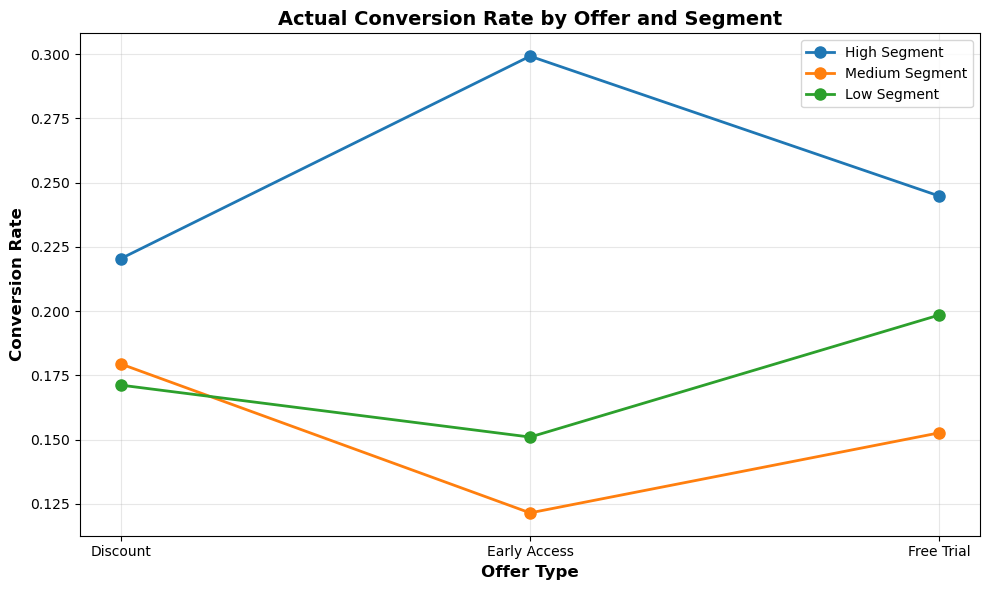

In [21]:
# Create visualization of actual conversion rates by offer and segment
actual_rates = test_analysis_df.groupby(['offer', 'segment'])['resubscribed_promo'].mean().reset_index()
actual_rates.columns = ['offer', 'segment', 'conversion_rate']

plt.figure(figsize=(10, 6))

for segment in ['High', 'Medium', 'Low']:
    segment_data = actual_rates[actual_rates['segment'] == segment]
    plt.plot(segment_data['offer'], segment_data['conversion_rate'], 
             marker='o', linewidth=2, markersize=8, label=f'{segment} Segment')

plt.xlabel('Offer Type', fontsize=12, fontweight='bold')
plt.ylabel('Conversion Rate', fontsize=12, fontweight='bold')
plt.title('Actual Conversion Rate by Offer and Segment', fontsize=14, fontweight='bold')
plt.legend(loc='best', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

We can see that each line (segment) has a different slope and a different peak.

#### Getting the predicted values

In the model output - we received coefficients. These coefficients are log-odds and are not directly interpretable. What we need is the actual predicted probabilities and not the log odds.

This step helps us see what the model predicted for each segment individually.


In [22]:
X.columns

Index(['Intercept', 'offer[T.Early Access]', 'offer[T.Free Trial]',
       'segment[T.Low]', 'segment[T.Medium]',
       'offer[T.Early Access]:segment[T.Low]',
       'offer[T.Free Trial]:segment[T.Low]',
       'offer[T.Early Access]:segment[T.Medium]',
       'offer[T.Free Trial]:segment[T.Medium]'],
      dtype='object')

We have 3 offers (Discount, Early Access, Free Trial) and 3 segments (High, Medium, Low), giving us a total of 9 combinations. What we want to know is - how did `Early Access` perform within the `Medium` segment?

We cannot directly compare the coefficients - because they are in log-odds and are not easy to understand and interpret.

For each combination, we create a "recipe" vector that tells the model: "Give me the predicted probability for this specific scenario." 

Think of it like filling out a form:
- **Intercept = 1**: Always include (it's the baseline)
- **Segment flags**: Set to 1 if this is your segment, 0 otherwise
  - High segment = all zeros (it's the reference)
  - Medium segment = set `segment[T.Medium]` to 1
  - Low segment = set `segment[T.Low]` to 1
- **Offer flags**: Set to 1 if this is your offer, 0 otherwise
  - Discount = all zeros (it's the reference)
  - Early Access = set `offer[T.Early Access]` to 1
  - Free Trial = set `offer[T.Free Trial]` to 1
- **Interaction terms**: Only turn on if both the offer AND segment are active
  - If we are looking at Low Segment Early Access Offer - we turn this specific interaction to 1.

**Example:** For "High Segment with Early Access offer":
- Turn ON: `Intercept` (1), `offer[T.Early Access]` (1)
- Turn OFF: everything else (0)

For each combination, the model predicts:
- **Predicted probability**: The conversion rate we expect
- **Standard error**: How confident we are in this prediction
- **Confidence interval**: The range where the true value likely falls

This gives us 9 predicted conversion rates, one for each offer-segment pairing. Once we get the predicted rates, we can compare them.

In [23]:
# Building the 6 predicted groups for the predicted probabilities
contrast_rows = {
    'High Segment Discount Offer':{
        'Intercept':1,
        'offer[T.Early Access]':0,
        'offer[T.Free Trial]':0, 
        'segment[T.Low]':0, 
        'segment[T.Medium]':0,
        'offer[T.Early Access]:segment[T.Low]':0,
        'offer[T.Free Trial]:segment[T.Low]':0,
        'offer[T.Early Access]:segment[T.Medium]':0,
        'offer[T.Free Trial]:segment[T.Medium]':0,
    },  
    'High Segment Early Access Offer':{
        'Intercept':1,
        'offer[T.Early Access]':1,
        'offer[T.Free Trial]':0, 
        'segment[T.Low]':0, 
        'segment[T.Medium]':0,
        'offer[T.Early Access]:segment[T.Low]':0,
        'offer[T.Free Trial]:segment[T.Low]':0,
        'offer[T.Early Access]:segment[T.Medium]':0,
        'offer[T.Free Trial]:segment[T.Medium]':0,
    },  
    'High Segment Free Trial Offer':{
        'Intercept':1,
        'offer[T.Early Access]':0,
        'offer[T.Free Trial]':1, 
        'segment[T.Low]':0, 
        'segment[T.Medium]':0,
        'offer[T.Early Access]:segment[T.Low]':0,
        'offer[T.Free Trial]:segment[T.Low]':0,
        'offer[T.Early Access]:segment[T.Medium]':0,
        'offer[T.Free Trial]:segment[T.Medium]':0,
    },
    'Medium Segment Discount Offer':{
        'Intercept':1,
        'offer[T.Early Access]':0,
        'offer[T.Free Trial]':0, 
        'segment[T.Low]':0, 
        'segment[T.Medium]':1,
        'offer[T.Early Access]:segment[T.Low]':0,
        'offer[T.Free Trial]:segment[T.Low]':0,
        'offer[T.Early Access]:segment[T.Medium]':0,
        'offer[T.Free Trial]:segment[T.Medium]':0,
    },  
    'Medium Segment Early Access Offer':{
        'Intercept':1,
        'offer[T.Early Access]':1,
        'offer[T.Free Trial]':0, 
        'segment[T.Low]':0, 
        'segment[T.Medium]':1,
        'offer[T.Early Access]:segment[T.Low]':0,
        'offer[T.Free Trial]:segment[T.Low]':0,
        'offer[T.Early Access]:segment[T.Medium]':1,
        'offer[T.Free Trial]:segment[T.Medium]':0,
    },  
    'Medium Segment Free Trial Offer':{
        'Intercept':1,
        'offer[T.Early Access]':0,
        'offer[T.Free Trial]':1, 
        'segment[T.Low]':0, 
        'segment[T.Medium]':1,
        'offer[T.Early Access]:segment[T.Low]':0,
        'offer[T.Free Trial]:segment[T.Low]':0,
        'offer[T.Early Access]:segment[T.Medium]':0,
        'offer[T.Free Trial]:segment[T.Medium]':1,
    },
    'Low Segment Discount Offer':{
        'Intercept':1,
        'offer[T.Early Access]':0,
        'offer[T.Free Trial]':0, 
        'segment[T.Low]':1, 
        'segment[T.Medium]':0,
        'offer[T.Early Access]:segment[T.Low]':0,
        'offer[T.Free Trial]:segment[T.Low]':0,
        'offer[T.Early Access]:segment[T.Medium]':0,
        'offer[T.Free Trial]:segment[T.Medium]':0,
    },  
    'Low Segment Early Access Offer':{
        'Intercept':1,
        'offer[T.Early Access]':1,
        'offer[T.Free Trial]':0, 
        'segment[T.Low]':1, 
        'segment[T.Medium]':0,
        'offer[T.Early Access]:segment[T.Low]':1,
        'offer[T.Free Trial]:segment[T.Low]':0,
        'offer[T.Early Access]:segment[T.Medium]':0,
        'offer[T.Free Trial]:segment[T.Medium]':0,
    },  
    'Low Segment Free Trial Offer':{
        'Intercept':1,
        'offer[T.Early Access]':0,
        'offer[T.Free Trial]':1, 
        'segment[T.Low]':1, 
        'segment[T.Medium]':0,
        'offer[T.Early Access]:segment[T.Low]':0,
        'offer[T.Free Trial]:segment[T.Low]':1,
        'offer[T.Early Access]:segment[T.Medium]':0,
        'offer[T.Free Trial]:segment[T.Medium]':0,
    },

}

predicted_probs = {}
for label, row in contrast_rows.items():
    contrast_X = pd.DataFrame([row], columns=X.columns)
    pred = model.get_prediction(contrast_X)
    summary = pred.summary_frame(alpha=0.1)
    predicted_probs[label] = {
        'predicted': summary['predicted'][0],
        'se': summary['se'][0],
        'ci_lower': summary['ci_lower'][0],
        'ci_upper': summary['ci_upper'][0]
    }

predicted_df = pd.DataFrame(predicted_probs).T.reset_index().rename(columns={'index':'Contrast'})
predicted_df

,Contrast,predicted,se,ci_lower,ci_upper
0,High Segment Discount Offer,0.220447,0.002766,0.215931,0.225030
1,High Segment Early Access Offer,0.299192,0.003051,0.294198,0.304235
2,High Segment Free Trial Offer,0.244780,0.002866,0.240097,0.249524
3,Medium Segment Discount Offer,0.179380,0.001673,0.176644,0.182149
4,Medium Segment Early Access Offer,0.121458,0.001424,0.119135,0.123820
5,Medium Segment Free Trial Offer,0.152597,0.001569,0.150034,0.155196
6,Low Segment Discount Offer,0.171167,0.001376,0.168916,0.173441
7,Low Segment Early Access Offer,0.150966,0.001309,0.148826,0.153131
8,Low Segment Free Trial Offer,0.198447,0.001457,0.196062,0.200854


The predicted values in each segment are similar to the actuals

In [24]:
# These actual values should be close to the predicted values from the model
actuals = test_analysis_df.groupby(['segment','offer'])['resubscribed_promo'].mean()
actuals

segment  offer       
High     Discount        0.220447
         Early Access    0.299192
         Free Trial      0.244780
Low      Discount        0.171167
         Early Access    0.150966
         Free Trial      0.198447
Medium   Discount        0.179380
         Early Access    0.121458
         Free Trial      0.152597
Name: resubscribed_promo, dtype: float64

Now, we have to see exactly by how much each offer is performing higher. 
In the `High` Segment, we see that `Early Access` has the highest response
In the `Medium` Segment, we see that `Discount` has the highest response
In the `Low` Segment, we see that `Free Trial` has the highest response

The model gave us coefficients or weights for each offer and segment combination. To compare two specific offers within the same segment, we need to make another comparison vector - think of it as a recipe for which variable's coefficients to add or subtract.

Each position in the vector represents one coefficient from the model
- A `1` means "include this coefficient"
- A `-1` means "subtract this coefficient"
- A `0` means "ignore this coefficient"

For example, to compare `Early Access` vs `Discount` in the `High` segment:
- We take the `High` Segment `Early Access` vector from the last step, and subtract the corresponding values in the `High` segment `Discount` vector from it.
We can also technically compare segments across offers - so we can compare how `High` segment customers performed compared to `Low` segment customers which both received a `Discount` offer. But this comparison does not make sense - because we already established which customer segments have what type of response.

The result tells us the log-odds difference between the two offers. We also calculate a standard error, which lets us determine if the difference is statistically significant (i.e., real and not just random chance).

This approach ensures we're making fair, apples-to-apples comparisons between offers within each segment.

In [25]:

params = model.params
cov = model.cov_params()

contrast_vectors = {'High Segment: Early Access - Discount'  : np.array([0 , 1, 0, 0, 0, 0, 0, 0, 0]),
                    'High Segment: Early Access - Free Trial': np.array([0 , 1,-1, 0, 0, 0, 0, 0, 0]),
                    'Medium Segment: Discount - Early Access': np.array([0 ,-1, 0, 0, 0, 0, 0,-1, 0]),
                    'Medium Segment: Discount - Free Trial'  : np.array([0 , 0,-1, 0, 0, 0, 0, 0,-1]),
                    'Low Segment: Free Trial - Early Access' : np.array([0 ,-1, 1, 0, 0,-1, 1, 0, 0]),
                    'Low Segment: Free Trial - Discount'     : np.array([0 , 0, 1, 0, 0, 0, 1, 0, 0]),
}

# Z critical value for 95% confidence
z_crit = norm.ppf(0.975)

# Number of comparisons for Bonferroni correction
k = len(contrast_vectors)

rows = []
for label, contrast in contrast_vectors.items():
    est = np.dot(contrast, params)
    se = np.sqrt(np.dot(contrast.T, np.dot(cov, contrast)))
    z_val = est / se
    p_val = 2 * (1 - norm.cdf(abs(z_val)))
    
    #Bonferroni correction
    p_val_bonf = min(p_val * k, 1)
    
    lower = est - z_crit * se
    upper = est + z_crit * se
    exp_est = np.exp(est)
    exp_lower = np.exp(lower)
    exp_upper = np.exp(upper)
    
    # These lifts and incremenal factors are calcualted in the odds space. If our incidence rate was lower, we could have calculated the lifts and incrementals correctly in this space, but given our high incidence rate(>10%), these will give exaggerated values and not be reflective of the true lift and incremental factor in the probability space.
    # lift = (exp_est - 1)*100 # (treatment - control) / control
    # factor = round((1 - (1 / (lift/100 + 1)))*100) # (treatment - control) / treatment

    # Extract segment name from label
    parts = label.split(': ')
    segment = parts[0]
    offers = parts[1].split(' - ')
    offer1 = offers[0]  # First offer (numerator)
    offer2 = offers[1]  # Second offer (denominator)
    
    # Get predicted probabilities
    offer1_key = f'{segment} {offer1} Offer'
    offer2_key = f'{segment} {offer2} Offer'
    offer1_prob = predicted_df[predicted_df['Contrast'] == offer1_key]['predicted'].values[0]
    offer2_prob = predicted_df[predicted_df['Contrast'] == offer2_key]['predicted'].values[0]
    
    # Calculate lift in probability space (offer1 - offer2) / offer2
    lift = ((offer1_prob - offer2_prob) / offer2_prob) * 100
    
    rows.append([label, est, se, z_val, p_val, p_val_bonf, lower, upper, exp_est, exp_lower, exp_upper, lift])

result_df = pd.DataFrame(rows, columns=[
    'Comparison', 
    'Estimate',
    'SE',
    'Z-value',
    'P-value',
    'P-value (Bonf)',
    'CI Lower',
    'CI Upper',
    'Exp(Estimate)',
    'Exp(CI Lower)',
    'Exp(CI Upper)',
    'Lift (%)'
    ])

result_df

,Comparison,Estimate,SE,Z-value,P-value,P-value (Bonf),CI Lower,CI Upper,Exp(Estimate),Exp(CI Lower),Exp(CI Upper),Lift (%)
0,High Segment: Early Access - Discount,0.411916,0.021696,18.985452,0.0,0.0,0.369391,0.454440,1.509707,1.446854,1.575291,35.720679
1,High Segment: Early Access - Free Trial,0.275500,0.021262,12.957677,0.0,0.0,0.233828,0.317172,1.317189,1.263428,1.373239,22.228880
2,Medium Segment: Discount - Early Access,0.458140,0.017531,26.133546,0.0,0.0,0.423781,0.492500,1.581131,1.527727,1.636402,47.688775
3,Medium Segment: Discount - Free Trial,0.193822,0.016627,11.657044,0.0,0.0,0.161234,0.226410,1.213880,1.174960,1.254090,17.551448
4,Low Segment: Free Trial - Early Access,0.331019,0.013714,24.136821,0.0,0.0,0.304139,0.357898,1.392386,1.355458,1.430320,31.451812
5,Low Segment: Free Trial - Discount,0.181354,0.013338,13.597220,0.0,0.0,0.155213,0.207495,1.198839,1.167906,1.230592,15.938023


#### Offer Performance Comparison

Based on the statistical analysis, we observe the following offer performance lifts within each segment:

- **High Segment**: Early Access offer lifts response over Discount offer by **35.72%**, and over Free Trial offer by **22.23%**

- **Medium Segment**: Discount offer lifts response over Early Access offer by **47.69%**, and over Free Trial offer by **17.55%**

- **Low Segment**: Free Trial offer lifts response over Early Access offer by **31.45%**, and over Discount offer by **15.94%**

All comparisons are statistically significant at p < 0.001, indicating that these performance differences are not due to chance.

A single offer/strategy would underperform atleast two out of three segments. Providing offers by segment is statistically justified and commercially meaningful for the company.

## Analysis 3 - Post-Resubscription Engagement